# Readout error mitigation by random bit flips

## The problem

Every result a quantum computer gives you ends with a **read-out**: the measurement that turns the qubit into a classical bit. The read-out misreads bits. A qubit that holds a 1 is read as a 0 a few percent of the time, because a qubit in $|1\rangle$ can decay to $|0\rangle$ while the measurement takes place. A qubit that holds a 0 is read as a 1 less often. The two errors differ. As a result every expectation value $\langle Z\rangle$ comes out wrong by an amount that depends on its value, and taking more shots does not remove this error.

Two words used throughout. The **bias** of a measurement is the measured value minus the true value. The **error bar** of a result is the typical size of its random scatter from one run to the next, from the finite number of shots (a *standard error*).

This notebook measures the read-out error and removes it in two ways.

1. **Correction 1: undo it with a matrix.** Measure how the read-out treats a 0 and a 1, write the result as a 2 x 2 matrix, and apply the inverse of the matrix to the data.
2. **Correction 2: randomly flip the bit before measuring, and flip the answer back afterward.** For each circuit a coin toss decides whether the flip happens. The error then becomes the same for a 0 and a 1, so it only multiplies $\langle Z\rangle$ by one number. We measure that number once and divide it out. The section "Randomly flipping the bit before measuring" in Step 1 builds this idea from small steps and gives it its standard name.

We test both on states whose true $\langle Z\rangle$ we know, so every corrected value can be compared with the truth. We compare their bias and their error bars, and we see how many coin tosses Correction 2 needs.

## The workflow

| Step | What it does | Code |
|---|---|---|
| 1. Operator | The observable $Z$, the true values of the test states, the read-out error model, and the random flip | `ops.py` |
| 2. Encoding | Build the calibration, sweep, and flipped circuits | `encoding.py` |
| 3. Execution | Run every circuit as one job and undo the flips in the counts | `execution.py` |
| 4. Analysis | Build the matrix, correct $\langle Z\rangle$ both ways, compare bias and error bars | `analysis.py` |

The same steps run from the command line with `python readout_mitigation/main.py`, started in `../scripts/`. The code lives in `../scripts/readout_mitigation/` and is imported below. Each module does one job:

- `ops.py` holds the observable, the true values $\cos\theta$, and the formulas of the read-out error model.
- `encoding.py` builds and compiles the circuits. `execution.py` runs them and undoes the flips in the counts.
- `analysis.py` turns counts into corrected $\langle Z\rangle$ with error bars, prints the tables, and draws the figures.

## Setup

By default this notebook runs on the Aer simulator (Qiskit's simulator for classical computers) with a read-out error that we chose: a 0 is read as 1 with probability 2%, and a 1 is read as 0 with probability 6%. Nothing else is noisy. Because we know the answer, we can check every correction against it. Set `backend_name = "ibm_rensselaer"` to measure a real qubit instead. The notebook then also runs IBM's own version of Correction 2: the Estimator options listed in the table "How IBM's names map to these steps" in Step 1. That path follows IBM's documented options. It has not been run on the device.

- `qubit`: the physical qubit to measure on hardware. Ignored on the simulator.
- `points`: number of test states in the sweep.
- `shots`: shots per test state.
- `randomizations`: the number $R$ of circuits among which the shots of one measurement are split. Each circuit gets its own coin toss: flip the bit before measuring, or do not. The flip makes the read-out error equal for a 0 and a 1.
- `seed`: seed of the coin tosses. `None` gives a different set each run, so numbers change by about their error bars.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from qiskit.quantum_info import Statevector

# The code lives in ../scripts/readout_mitigation.
# Run this notebook from its own folder (the Jupyter default).
sys.path.insert(0, str(Path("../scripts/readout_mitigation").resolve()))

import analysis
import encoding as enc
import execution
import ops

%matplotlib inline

backend_name = None  # None = Aer simulator, or e.g. "ibm_rensselaer"
qubit = 0  # physical qubit, hardware only
points = 13
shots = 4000
randomizations = 20
seed = None

## Step 1: The operator

### The observable and the true values

The Estimator and the counts of earlier notebooks give the **expectation value** $\langle Z\rangle$. Each shot returns the outcome 0 or 1. Give the outcome 0 the value $+1$ and the outcome 1 the value $-1$. The average value over many shots is then $\langle Z\rangle = P(0) - P(1)$, where $P(0)$ and $P(1)$ are the probabilities to read 0 and 1. It is $+1$ for a qubit in $|0\rangle$ and $-1$ for a qubit in $|1\rangle$.

To test a correction we need states whose $\langle Z\rangle$ we know without measuring. The gate $R_Y(\theta)$ rotates a qubit from $|0\rangle$ toward $|1\rangle$ by an angle $\theta$. It makes the state $\cos(\theta/2)\,|0\rangle + \sin(\theta/2)\,|1\rangle$, so $P(0) = \cos^2(\theta/2)$ and $P(1) = \sin^2(\theta/2)$. Then

$$\langle Z\rangle = \cos^2(\theta/2) - \sin^2(\theta/2) = \cos\theta.$$

Check at three angles: $\theta = 0$ gives $+1$ (the state is $|0\rangle$), $\theta = \pi/2$ gives $0$ (equal probabilities), and $\theta = \pi$ gives $-1$ (the state is $|1\rangle$). The sweep uses `points` angles from $0$ to $\pi$, so the true $\langle Z\rangle$ runs over the whole range from $+1$ to $-1$.

`Statevector` computes the exact noiseless answer from the amplitudes, with no sampling. The next cell compares it with $\cos\theta$ at the three angles above and at a fourth, $\theta = 1.0$ rad, that has no special value.

In [2]:
from qiskit import QuantumCircuit

z_op = ops.observable()
print(f"{'theta':>10} {'statevector':>12} {'cos(theta)':>11}")
for theta in [0, np.pi / 2, np.pi, 1.0]:
    state = QuantumCircuit(1)
    state.ry(theta, 0)
    value = Statevector(state).expectation_value(z_op).real
    print(f"{theta:>10.4f} {value:>12.4f} {ops.ideal_z(theta):>11.4f}")

     theta  statevector  cos(theta)
    0.0000       1.0000      1.0000
    1.5708       0.0000      0.0000
    3.1416      -1.0000     -1.0000
    1.0000       0.5403      0.5403


### What the read-out does to a bit

A perfect read-out would report the bit that the qubit holds. Ours does not. The simulator's read-out behaves like this:

| The qubit holds | Read as 0 | Read as 1 |
|---|---|---|
| 0 | 98% | 2% |
| 1 | 6% | 94% |

Two numbers describe the table. Let $p_{01}$ be the probability to read 1 when the qubit holds 0 (first index: the bit held, second index: the bit read). Here $p_{01} = 0.02$. Let $p_{10}$ be the probability to read 0 when it holds 1, here $0.06$. The table as a 2 x 2 matrix is the **confusion matrix** $C$. Column $j$ is the bit that the qubit holds, row $i$ is the bit that was read, and each column adds up to 1:

$$C = \begin{pmatrix} 1 - p_{01} & p_{10} \\ p_{01} & 1 - p_{10} \end{pmatrix} = \begin{pmatrix} 0.98 & 0.06 \\ 0.02 & 0.94 \end{pmatrix}.$$

If the true probabilities are $P(0)$ and $P(1)$, the read-out reports $P_m(0) = (1 - p_{01})P(0) + p_{10}P(1)$ and $P_m(1) = p_{01}P(0) + (1 - p_{10})P(1)$ (the subscript $m$ means measured). Subtract them:

$$\langle Z\rangle_m = P_m(0) - P_m(1) = (1 - 2p_{01})\,P(0) - (1 - 2p_{10})\,P(1).$$

Now write $P(0) = (1+z)/2$ and $P(1) = (1-z)/2$, where $z$ is the true $\langle Z\rangle$:

$$\langle Z\rangle_m = \tfrac12\left[(1 - 2p_{01})(1 + z) - (1 - 2p_{10})(1 - z)\right] = (p_{10} - p_{01}) + (1 - p_{01} - p_{10})\,z.$$

Give the two coefficients names:

$$\langle Z\rangle_m = a\,z + b, \qquad a = 1 - p_{01} - p_{10}, \qquad b = p_{10} - p_{01}.$$

The factor $a$ (the **attenuation**) shrinks $\langle Z\rangle$ toward 0. The shift $b$ pushes it up when 1s are misread more often than 0s. Here $a = 0.92$ and $b = 0.04$.

**Worked example.** A qubit has true $\langle Z\rangle = -0.6$, so $P(0) = 0.2$ and $P(1) = 0.8$.

1. $P_m(0) = 0.98 \times 0.2 + 0.06 \times 0.8 = 0.196 + 0.048 = 0.244$, so $P_m(1) = 0.756$.
2. $\langle Z\rangle_m = 0.244 - 0.756 = -0.512$.

Check with the formula: $a z + b = 0.92 \times (-0.6) + 0.04 = -0.552 + 0.04 = -0.512$. The two agree. The measured value is $0.088$ above the truth, so the bias is $+0.088$.

### Randomly flipping the bit before measuring

The bias has two parts, $a$ and $b$. The part $b$ exists only because the error is *asymmetric*: $p_{01} \ne p_{10}$. If the two errors were equal, $b$ would be zero. The idea of this section is to make the two errors equal on purpose. We build it in five small steps. It uses only what we have: bits, the X gate (a bit flip), counts, and probabilities.

**(a) The read-out error of each bit.** From the table above, a 0 is misread 2% of the time and a 1 is misread 6% of the time.

**(b) Flip the bit with an X gate first.** Put an X gate on the qubit immediately before the measurement, and flip the *classical answer* back afterward (turn every 0 in the counts into a 1 and every 1 into a 0). Look at each case.

| True bit (before the X) | Qubit holds after the X | Read-out error of that bit | Answer after flipping back | Chance the answer is wrong |
|---|---|---|---|---|
| 0 | 1 | 6% | 0 | 6% |
| 1 | 0 | 2% | 1 | 2% |

Without the X, a 0 is wrong 2% of the time and a 1 is wrong 6% of the time. With the X, the two exchange. A 0 is wrong 6% of the time and a 1 is wrong 2% of the time. Always flipping does not remove the asymmetry. It moves it to the other bit.

**(c) Choose the flip by a coin toss.** Build many circuits. For each circuit, toss a coin. On heads, add the X to that circuit and flip its answers back. On tails, change nothing. All the shots of one circuit share its toss. Call one such circuit, with its coin toss, a **randomization**, and let $R$ be the number of them. With equal shots in each, about half of all shots have the X. Take a true 0. The chance that a shot is wrong is $6\%$ if it had the X and $2\%$ if not. Because the probability of a mixture is the weighted average of the probabilities of its parts, half and half gives $(2\% + 6\%)/2 = 4\%$. A true 1 is wrong with $2\%$ in the half with the X and $6\%$ in the other half, so also $4\%$. The average error is the same for both bits. Call it $e = (p_{01} + p_{10})/2 = 0.04$.

**(d) A symmetric error multiplies $\langle Z\rangle$ by one factor.** Take a true 0. Half of the shots have no X and see the error rate $p_{01}$. The other half have the X, so the qubit holds a 1 and sees the error rate $p_{10}$. Each shot belongs to exactly one of the two cases, so the overall fraction of correct reads is the weighted average of the two fractions: $\tfrac12(1 - p_{01}) + \tfrac12(1 - p_{10}) = 1 - e$. A true 1 gives the same number. Averaging two probabilities that each come from a fixed error rate is the same as using the average error rate. So the coin tosses act like a read-out that misreads both bits with the probability $e$. If both bits are misread with probability $e$, then $P_m(0) = (1-e)P(0) + e\,P(1)$ and $P_m(1) = (1-e)P(1) + e\,P(0)$. Subtract:

$$\langle Z\rangle_m = (1-e)\,[P(0) - P(1)] - e\,[P(0) - P(1)] = (1 - 2e)\,\langle Z\rangle.$$

The shift $b$ is gone, and what remains is one factor, $1 - 2e$. It equals $a$, because $1 - 2e = 1 - p_{01} - p_{10}$. Here $1 - 2 \times 0.04 = 0.92$.

**(e) Measure the factor once and divide it out.** A qubit in $|0\rangle$ has a true $\langle Z\rangle$ of exactly $+1$. Measure it with the coin-toss flips. The result is $(1 - 2e) \times 1$, which is the factor itself. Divide any later $\langle Z\rangle_m$ from coin-toss flips by it. One calibration state is enough, and we never needed to know $p_{01}$ and $p_{10}$ separately.

The whole procedure is called **Pauli twirling**: choose at random which of the gates $I$ (do nothing), X, Y, Z to apply before the measurement, and undo that choice in the answer afterward. *Twirling* is the standard name for averaging an error over randomly chosen gates, so that what is left has a simpler form. *Pauli* names the family $I$, X, Y, Z (the Pauli gates of Unit 1). For a general measurement all four matter. For a $Z$ measurement only the bit flip matters, so we use the one-gate version with X. Here is why. The gates $I$ and $Z$ change no counts: $Z$ changes only the phase, which is the angle between the amplitudes of $|0\rangle$ and $|1\rangle$, and counts depend only on the sizes of the amplitudes. The gate $Y$ flips the bit exactly like X, and its extra phase is invisible to the counts in the same way.

**Worked example, continued.** Take the same qubit as before, $P(0) = 0.2$ and $P(1) = 0.8$, with $e = 0.04$.

1. With the coin tosses: $P_m(0) = 0.96 \times 0.2 + 0.04 \times 0.8 = 0.192 + 0.032 = 0.224$, so $P_m(1) = 0.776$.
2. $\langle Z\rangle_m = 0.224 - 0.776 = -0.552$.
3. Divide by the factor measured on $|0\rangle$: $-0.552 / 0.92 = -0.6$.

Check: $(1 - 2e)\langle Z\rangle = 0.92 \times (-0.6) = -0.552$, as in step 2, and step 3 returns the true value. Without twirling the same qubit read $-0.512$, off by $0.088$.

**Why the shift $b$ cancels, and what a finite $R$ leaves.** Take one circuit with the X. After the X the circuit holds the opposite bit, so the true value that the read-out sees is $-z$. The read-out reports $a(-z) + b$. The classical flip then multiplies the answer by $-1$ again: $-[a(-z) + b] = a z - b$. So the shift is $+b$ in a circuit without the X and $-b$ in a circuit with it. If a fraction $f$ of the shots has the X, the average is $a z + b(1 - 2f)$. With equal weights, $f = 1/2$, the shift is zero. With $R$ coin tosses the number of circuits with the X is $R/2$ plus or minus about $\sqrt{R}/2$ (the spread of a fair coin tossed $R$ times). So $f$ is off from $1/2$ by about $1/(2\sqrt{R})$, and the weight imbalance $1 - 2f$ is about $1/\sqrt{R}$. That imbalance multiplies $b$, so the leftover shift has a typical size of $b/\sqrt{R}$. For $R = 1$ it is $\pm b$: the one coin toss decides the sign.

**Fill in by hand before running any code.** Take a qubit with true $\langle Z\rangle = +0.6$, so $P(0) = 0.8$ and $P(1) = 0.2$, with the same read-out ($p_{01} = 0.02$, $p_{10} = 0.06$).

| | $P_m(0)$ | $\langle Z\rangle_m$ | Bias |
|---|---|---|---|
| No flips | | | |
| Coin-toss flips ($e = 0.04$) | | | |
| Coin-toss flips, divided by $0.92$ | not needed | | |

The answers are in the next section.

## Stop and think: what does the random flip do?

1. **Fill-in table: what are the numbers?** No flips: $P_m(0) = 0.98 \times 0.8 + 0.06 \times 0.2 = 0.796$, so $\langle Z\rangle_m = 0.796 - 0.204 = 0.592$, bias $-0.008$. Coin-toss flips: $P_m(0) = 0.96 \times 0.8 + 0.04 \times 0.2 = 0.776$, so $\langle Z\rangle_m = 0.776 - 0.224 = 0.552$. Divided by $0.92$: $0.6$, bias $0$. *Why is the unflipped bias so small here?* The shift $b = +0.04$ and the shrinking by $a$ nearly cancel at $\langle Z\rangle = 0.6$ (exactly at $0.5$). Away from there the bias is larger, which is why the sweep covers all values.
2. **Does the random X change the state we are measuring?** The ideal answer does not change. The X flips the bit that the read-out sees. The software flip of the answer undoes that in the counts, so the ideal answer is unchanged. What changes is which read-out error the bit meets: a true 0 meets the error of a 1, and the other way round.
3. **Why not always flip?** Always flipping swaps the two errors between the bits and leaves the difference in place (step (b)). Only the random choice averages them, because half of the shots meet each error.
4. **Is this twirling, or only relabeling the answer?** Swapping 0 and 1 in the counts afterward does not change how often the read-out is wrong. The X is applied to the qubit before the read-out, so the read-out acts on the other bit: a true 0 meets the 6% error.
5. **What does the twirl cost?** Dividing by $0.92$ makes every error bar $1/0.92 \approx 1.09$ times larger, and the coin tosses add scatter of their own.

### How IBM's names map to these steps

IBM's Qiskit Runtime offers this method through options of its Estimator. Each name refers to a step above.

| IBM name | What it is | Step above |
|---|---|---|
| `twirling.enable_measure = True` | **Measurement twirling**: add a random X before each measurement and flip the answer back | (b) and (c) |
| `twirling.num_randomizations` | Number of randomizations $R$ | (c) |
| `twirling.shots_per_randomization` | Shots in each randomization (circuit) | (c) |
| `resilience.measure_mitigation = True` | Turn on **TREX** (twirled readout error extinction): divide the result by the learned factor | (d) and (e) |
| `resilience.measure_noise_learning` | How IBM measures the factor: twirled runs of a state with a known answer | (e) |

## Step 2: Encoding

Every circuit has one qubit and one classical bit. There are three kinds.

- **Calibration:** prepare $|0\rangle$ or $|1\rangle$ and measure. These measure $p_{01}$ and $p_{10}$.
- **Sweep:** apply $R_Y(\theta)$ and measure.
- **Twirled:** the same circuit with an X gate immediately before the measurement. The answer is flipped back after the run, in Step 3.

The figure shows the sweep circuit at $\theta = \pi/2$ without and with the flip. A **barrier** (the dashed line) stops the compiler from merging gates across it. To *compile* a circuit is to convert it to the gates that the device runs (Qiskit calls this transpiling). We compile with the **optimizer** off. The optimizer is the step that rewrites a circuit into a shorter one that does the same thing, and it could fold the X into the gate before it and delete the twirl.

Without the flip


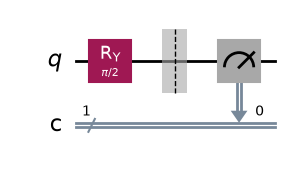

With the flip


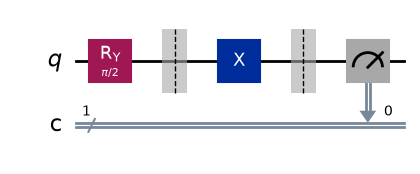

In [3]:
plain = enc.sweep_circuit(np.pi / 2, flip=False)
twirled = enc.sweep_circuit(np.pi / 2, flip=True)
for label, circuit in [("Without the flip", plain), ("With the flip", twirled)]:
    print(label)
    fig = circuit.draw("mpl")
    display(fig)
    plt.close(fig)  # keep the inline backend from drawing it a second time

## Stop and think: what did the encoding decide?

1. **How do the two circuits differ?** By one gate. The flipped circuit has an X before the measurement and nothing else is different, so any difference in the results comes from that gate.
2. **How many versions of each circuit exist?** Two: with the flip or without. The coin tosses only choose between the two compiled versions, so we compile each once.
3. **Why can the calibration states measure the read-out?** Their answers are known: $|0\rangle$ has $\langle Z\rangle = +1$ and $|1\rangle$ has $-1$, whatever the device does.

## Step 3: Execution

All circuits run as one job: on hardware the queue wait is paid once per job. The job holds four groups.

1. The two calibration states, $|0\rangle$ and $|1\rangle$, without flips (1 circuit each, 20000 shots each).
2. The same two states with coin-toss flips (100 randomizations each, 200 shots per circuit). The number is large on purpose: every sweep point is divided by the result, so its error is shared by all of them.
3. The sweep without flips (1 circuit per angle, `shots` shots).
4. The sweep with coin-toss flips (`randomizations` circuits per angle, `shots` shots divided among them).

With the default settings that is $2 + 2 \times 100 + 13 + 13 \times 20 = 475$ circuits.

After the job returns, the counts of every circuit that had an X are flipped back: the numbers of 0s and 1s are exchanged. From then on all counts are in the bit labels of the ideal circuit.

On the simulator, the read-out error is the only noise, so the result can be checked against the built-in values. On hardware the device supplies its own, and one more job runs: the Estimator with IBM's options from the table above. This part is not run here, because it needs hardware.

```python
estimator = EstimatorV2(mode=backend)
estimator.options.resilience_level = 0                  # everything off ...
estimator.options.resilience.measure_mitigation = True  # ... except TREX
estimator.options.twirling.enable_measure = True        # ... and measurement twirling
```

The names were checked against the installed `qiskit_ibm_runtime` (version 0.49) by setting them on an options object. They were not run on a device.

In [4]:
data = execution.run(
    points,
    shots,
    randomizations,
    backend_name,
    qubit if backend_name else None,
    seed,
)
print(f"\nTotal time: {data['seconds']:.0f} s")

  475 circuits in one job

 (1 s)

Total time: 1 s


## Step 4: Analysis

### The read-out error from the calibration

The two calibration states give $p_{01}$ (the fraction of 1s read for $|0\rangle$) and $p_{10}$ (the fraction of 0s read for $|1\rangle$). The table also shows $a$ and $b$, and the factor $a$ read from the twirled $|0\rangle$ as in step (e). Each number comes with its error bar and, on the simulator, the value that was built in.

                                             measured   built in
p01 (read 1 when the bit is 0)        0.0188 +/- 0.0010     0.0200
p10 (read 0 when the bit is 1)        0.0594 +/- 0.0017     0.0600
a = 1 - p01 - p10                     0.9218 +/- 0.0019     0.9200
b = p10 - p01                         0.0406 +/- 0.0019     0.0400
a from the twirled |0>                0.9250 +/- 0.0047     0.9200

column sums of the confusion matrix: [1. 1.]


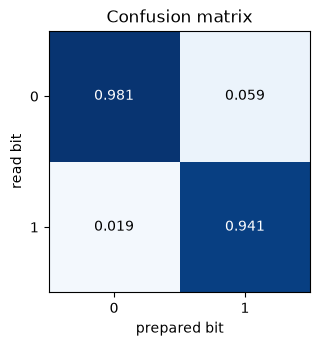

In [5]:
res = analysis.estimates(data)
analysis.print_calibration(data, res)
print("\ncolumn sums of the confusion matrix:", res["cal"]["matrix"].sum(axis=0))
fig = analysis.plot_confusion(res["cal"])

The columns add up to 1, as they must: every prepared bit is read as something. The off-diagonal entries are the errors, and the lower-left one is smaller than the upper-right one. The factor $a$ from the twirled $|0\rangle$ and the value $1 - p_{01} - p_{10}$ from the two untwirled states are two measurements of one number. They agree to within about one to two error bars, which supports step (d).

### The bias on $\langle Z\rangle$

Now the sweep. For each test state we know the true $\langle Z\rangle$. Without any correction, the measured values should fall on the line $a z + b$ and not on the line of equal values.

bias at ideal  +1: -0.041
bias at ideal   0: +0.051
bias at ideal  -1: +0.129


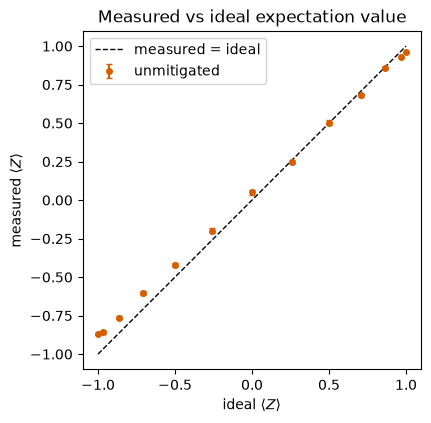

In [6]:
fig = analysis.plot_bias(res)
unm = res["unmitigated"]
print(f"bias at ideal  +1: {unm['z'][0] - res['ideal'][0]:+.3f}")
print(f"bias at ideal   0: {unm['z'][points // 2] - res['ideal'][points // 2]:+.3f}")
print(f"bias at ideal  -1: {unm['z'][-1] - res['ideal'][-1]:+.3f}")

The points lie below the dashed line near $+1$ and above it near $-1$, with the largest gap at $-1$. That is the expected shape: $a z + b$ with $a < 1$ and $b > 0$. At $\langle Z\rangle = -1$ the true state is $|1\rangle$, which has the larger error. The biases in the printout are several times the error bar of one point (about $0.01$), so shot noise cannot explain them.

### Correction 1: invert the confusion matrix

If the read-out maps the true probabilities $(P(0), P(1))$ to the measured ones by $C$, then applying $C^{-1}$ (the inverse matrix) to the measured probabilities gives the true ones. For our $C$ the inverse is

$$C^{-1} = \frac{1}{0.92}\begin{pmatrix} 0.94 & -0.06 \\ -0.02 & 0.98 \end{pmatrix}.$$

The number in front, $1/0.92$, is the inverse of the determinant of $C$. Check with the worked example: the measured probabilities were $(0.244, 0.756)$.

In [7]:
C = ops.confusion_matrix(*execution.SIM_READOUT)
print("C inverse:\n", np.round(np.linalg.inv(C), 4))
print(
    "C inverse times (0.244, 0.756):", np.round(np.linalg.solve(C, [0.244, 0.756]), 4)
)
print("determinant of C:", round(np.linalg.det(C), 4))

C inverse:
 [[ 1.0217 -0.0652]
 [-0.0217  1.0652]]
C inverse times (0.244, 0.756): [0.2 0.8]
determinant of C: 0.92


We get $(0.2, 0.8)$, the true probabilities. In the sweep the matrix is the *measured* $C$ from the calibration states, so its own error is added to the error bar (`analysis.invert` does this).

The method has two weaknesses.

- **It needs a full calibration.** A matrix for $n$ qubits has $2^n$ columns, one for every bit string, so it needs $2^n$ calibration circuits. The table counts them.
- **It amplifies noise.** The inverse has entries larger than 1 ($0.98/0.92 \approx 1.07$ here). The correction multiplies every error bar by about $1/a$, and for a product of $Z$ on $n$ qubits by about $1/a^n$ (see the note below the table). The inverted data can also fall outside the allowed range: a corrected probability can be negative, or a corrected $\langle Z\rangle$ can exceed $1$, when the data are near an end of the range.

For twirling, the calibration is one circuit: the twirled $|0\ldots0\rangle$. The reasoning: if the read-out errors of different qubits are independent, the twirl multiplies the $Z$ of qubit $k$ by its own factor $a_k$. A product of $Z$ on several qubits is then multiplied by the product of their factors, and the twirled $|0\ldots0\rangle$ (true value $+1$ for every such product) measures all of them. For errors that are correlated between qubits we state, without proof here, that the same one-circuit calibration still works for each product of $Z$, with a separate factor for each product. The table uses equal factors $a$ on every qubit.

In [8]:
a = res["cal"]["a"]
print(
    f"{'qubits n':>9} {'matrix size':>12} {'calibration circuits':>21} {'twirled calibration circuits':>29} {'error factor 1/a^n':>19}"
)
for n in range(1, 7):
    print(f"{n:>9} {f'{2**n} x {2**n}':>12} {2**n:>21} {1:>29} {1 / a**n:>19.2f}")

 qubits n  matrix size  calibration circuits  twirled calibration circuits  error factor 1/a^n
        1        2 x 2                     2                             1                1.08
        2        4 x 4                     4                             1                1.18
        3        8 x 8                     8                             1                1.28
        4      16 x 16                    16                             1                1.39
        5      32 x 32                    32                             1                1.50
        6      64 x 64                    64                             1                1.63


For one qubit, neither weakness hurts. The calibration is two circuits and the amplification is $1/0.92 \approx 1.09$. The table shows how both grow with the size of the circuit. The error factor $1/a^n$ applies to the twirled method too, because dividing by the factor enlarges the error bar in both. The saving from twirling is in the number of calibration circuits.

### The error rate before and after the random flip

Before we correct anything, check the claim of steps (b) and (c): with coin-toss flips, a true 0 and a true 1 should be misread equally often. The figure and the printout show the fraction of wrong answers for each true bit, from the calibration runs, with its error bar.

plain    true 0 wrong: 1.88 +/- 0.10%   true 1 wrong: 5.94 +/- 0.17%
twirled  true 0 wrong: 3.75 +/- 0.13%   true 1 wrong: 3.91 +/- 0.14%
average of the two untwirled rates: 3.91%


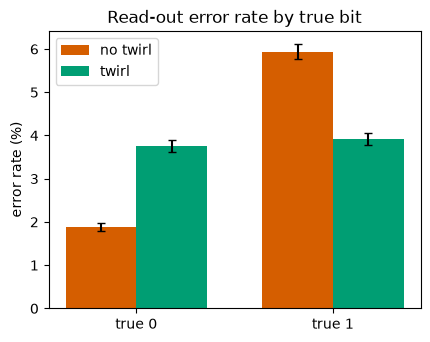

In [9]:
fig = analysis.plot_error_rates(data)
rates = analysis.error_rates(data)
for key in ("plain", "twirled"):
    (r0, e0), (r1, e1) = rates[key]
    print(
        f"{key:<8} true 0 wrong: {100 * r0:.2f} +/- {100 * e0:.2f}%   "
        f"true 1 wrong: {100 * r1:.2f} +/- {100 * e1:.2f}%"
    )
print(
    f"average of the two untwirled rates: {50 * (rates['plain'][0][0] + rates['plain'][1][0]):.2f}%"
)

Without the twirl the two bars differ, about 2% and 6%. With it, both are close to 4%, the average of the two. This is the symmetric error of step (c). The two twirled rates differ by a few tenths of a percentage point at most. The printed error bars cover only the shot noise. The rest of the difference is the leftover from an uneven number of heads and tails among the 100 coin tosses (see "Why the shift $b$ cancels" above), and it changes from run to run.

### Correction 2: twirl and rescale

The twirled sweep gives $\langle Z\rangle_m = a z$ for each state. Dividing by the factor $a$ from the twirled $|0\rangle$ gives the corrected value. The error bar of a twirled value is the spread of the randomizations divided by $\sqrt{R}$ (their standard error). It includes the leftover from an uneven number of heads and tails, and the error bar of the factor is added.

### The three methods on one plot

The upper panel shows the estimates and the ideal curve $\cos\theta$. The lower panel shows each estimate minus the ideal value, called the **residual**. If a method has no bias, its residuals scatter around zero within their error bars. The points of the three methods are shifted sideways a little so that their error bars do not cover each other.


method                    mean bias  max |bias|  error bar
unmitigated                  +0.039       0.129      0.011
matrix inversion             -0.002       0.034      0.012
twirled and rescaled         +0.004       0.036      0.016
twirled, not rescaled        +0.004       0.082      0.014


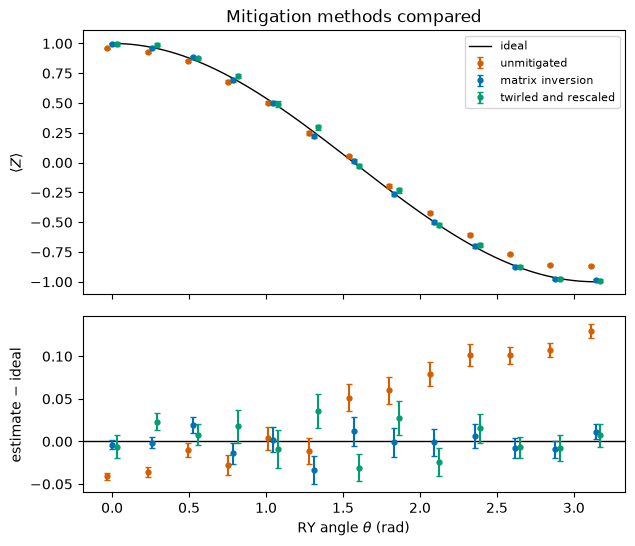

In [10]:
fig = analysis.plot_compare(res)
print()
analysis.print_bias(res)

The table gives the mean residual (the bias averaged over the sweep), the largest residual in magnitude, and the average error bar of each method. The row "twirled, not rescaled" shows what the factor $a$ alone does: its mean residual is near zero because the shift $b$ is gone, but its largest residual is still large, because $\langle Z\rangle$ is multiplied by $0.92$.

### Are the error bars honest?

An error bar is honest if the residuals scatter around zero by about that much. For each point, divide the residual by its error bar. If the error bars are right, these ratios have a standard deviation of 1. The cell repeats the whole sweep 30 times and computes it for both corrections.

In [11]:
import contextlib
import io

if backend_name is None:
    ratios = {"inverted": [], "rescaled": []}
    for _ in range(30):
        with contextlib.redirect_stdout(io.StringIO()):  # hide the job messages
            rerun = execution.run(points, shots, randomizations, None, None, None)
        again = analysis.estimates(rerun)
        for name, values in ratios.items():
            values.extend((again[name]["z"] - again["ideal"]) / again[name]["err"])
    for name, values in ratios.items():
        print(
            f"{analysis.LABELS[name]:<22} mean {np.mean(values):+.2f}, "
            f"standard deviation {np.std(values):.2f} (ideal: 0 and 1)"
        )
else:
    print("The repeats run on the simulator only.")

matrix inversion       mean -0.08, standard deviation 1.01 (ideal: 0 and 1)
twirled and rescaled   mean -0.04, standard deviation 1.03 (ideal: 0 and 1)


## Stop and think: reading the comparison

1. **Did both corrections remove the bias?** Yes. The mean residual of the unmitigated data is about $+0.04$, which is $b$. After either correction the mean is near $0$, and the largest residual is two to three error bars, as expected for the largest of 13 points.
2. **Why are the corrected error bars larger?** Dividing by $a$ enlarges the error bar, and a twirled value adds the scatter of the random flips. Mitigation trades bias for scatter. The trade is good when the bias is the larger of the two, as it is here (up to about $0.12$ against $0.01$).
3. **Which method is better for one qubit?** About equal. They have the same bias, and the twirled error bar is somewhat larger (about $0.015$ against $0.012$). The difference shows up when the circuit grows, as in the table above.
4. **Are the residuals of the twirled points independent?** No. All twirled points are divided by the same factor, so its error moves all of them together. This is why the calibration uses 100 randomizations.

### How many randomizations?

Step 1 showed that with $R$ coin tosses a leftover shift of typical size $b/\sqrt{R}$ remains. Take a state with true $\langle Z\rangle = 0$ and a fixed total of $N = 4000$ shots, split over $R$ circuits. The error bar of the rescaled value then has two independent parts: the shot noise, and the leftover shift. Independent errors **add in quadrature**: square each, add the squares, and take the square root. Dividing by the factor $a$ gives

$$\sigma(R) = \frac{1}{a}\sqrt{\frac{1}{N} + \frac{b^2}{R}}.$$

The first term is the shot noise, which does not depend on $R$. The second shrinks as $R$ grows. Check with $R = 1$: $\sigma = \frac{1}{0.92}\sqrt{1/4000 + 0.04^2} \approx 0.047$. With $R = 64$ the second term is small and $\sigma \approx 0.018$.

The simulation repeats the whole measurement 100 times for each $R$, with new coin tosses each time. The standard deviation of the 100 results is the error bar that one run would have. (Simulator only.)

R =  1: error bar 0.045, mean +0.006
R =  2: error bar 0.037, mean +0.001
R =  4: error bar 0.028, mean -0.001
R =  8: error bar 0.023, mean -0.004
R = 16: error bar 0.018, mean -0.004
R = 32: error bar 0.019, mean +0.000
R = 64: error bar 0.016, mean -0.002


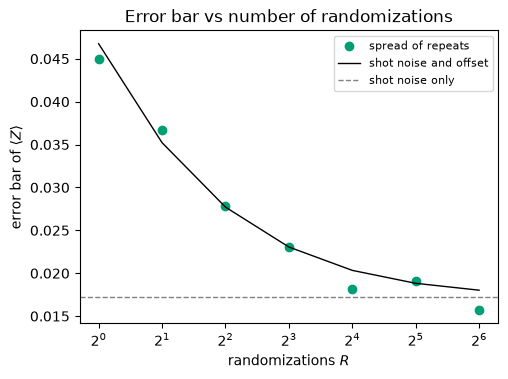

In [12]:
if backend_name is None:
    study = execution.randomization_study(seed=seed)
    truth = ops.simulator_truth()
    fig = analysis.plot_randomizations(study, truth["a"], truth["b"])
    for c in study["counts"]:
        print(
            f"R = {c:>2}: error bar {np.std(study['estimates'][c], ddof=1):.3f}, "
            f"mean {np.mean(study['estimates'][c]):+.3f}"
        )
else:
    print("The randomization study needs many repeats and runs on the simulator only.")

The spread falls from about $0.05$ at $R = 1$ to about $0.02$ at $R = 16$ and then flattens. The flat level is the shot noise, which only more shots can lower. The solid line is the formula above and the points follow it. On hardware every randomization is a separate circuit, with its own overhead, so a middle value of $R$ is the practical choice: enough to remove the leftover shift without sending thousands of circuits.

## Reading the results

The numbers below are for the simulator with the default settings. The coin tosses and the shots are random, so a rerun changes them by about their error bars.

- **The read-out error is measured well.** $p_{01}$ comes out near $0.02$ and $p_{10}$ near $0.06$, so $a \approx 0.92$ and $b \approx 0.04$.
- **The unmitigated bias depends on the state.** It is about $-0.04$ at $\langle Z\rangle = +1$, about $+0.03$ to $+0.05$ near $0$, and about $+0.12$ at $\langle Z\rangle = -1$. More shots would not shrink it.
- **The random flip makes the error symmetric.** Both bits are misread about 4% of the time, the average of 2% and 6%.
- **Both corrections remove the bias.** The mean residual drops from about $+0.04$ to within about $0.01$ of zero. The error bars are about $0.012$ (inversion) and $0.015$ to $0.017$ (twirl and rescale), against about $0.011$ without correction.
- **The error bars are honest.** In the repeated sweeps above, the ratio of residual to error bar has a standard deviation close to 1 for both corrections. The largest of 13 residuals in one run can still reach three error bars.
- **The error bar of the twirl depends on $R$.** With $R = 1$ the leftover shift dominates. From $R \approx 16$ on, the shot noise does.

On hardware, expect these differences.

- **Larger and drifting read-out errors.** The values of $p_{01}$ and $p_{10}$ change with the qubit and from hour to hour, so the calibration must be measured close in time to the data.
- **Errors that depend on neighbors.** On many qubits, the read-out of one qubit can depend on the others. The matrix then has to cover all of them. The twirled factor still works for each product of $Z$ operators, but each product has its own factor.
- **Errors that are not read-out errors.** The methods here fix the measurement only. Errors in gates before the measurement remain.

## What to try next

1. Change `SIM_READOUT` in `ops.py` to `(0.04, 0.04)`. Which bias is left to remove, and what does the twirl change? Then try `(0.0, 0.10)`.
2. Set `randomizations = 2`, then `100`. How does the error bar of the twirled estimate change, and when does it stop improving?
3. Set `shots = 400`, then `40000`. Which of the three error bars changes most? Is there a shot count where mitigation is not worth it?
4. In `execution.py`, replace the random choice of flips by exactly half heads and half tails (an alternating pattern). What happens to the leftover shift in the study of $R$?
5. Look at the table of qubit counts. Compute $1/a^n$ for $n = 20$ with $a = 0.92$. What does this say about measuring $Z$ on all 20 qubits?
6. Add a second qubit in `encoding.py` and measure the product of the two $Z$ outcomes (multiply the $\pm1$ values of the two qubits in each shot), with an independent coin toss on each qubit. Predict the factor from the two single-qubit values of $a$, then check it on the twirled $|00\rangle$.
7. Run on `ibm_rensselaer` with `qubit = 0`, then with a different qubit. Compare $p_{01}$ and $p_{10}$ with the read-out error on the backend's calibration page. Which qubit has the larger asymmetry $b$?
8. On hardware, compare the twirled and rescaled column of the table with the IBM Estimator row. Do they agree within their error bars?

## Terms

| Term | Plain definition | First used |
|---|---|---|
| read-out | The measurement that turns a qubit into a classical bit | The problem |
| bias | Measured value minus true value | The problem |
| error bar (standard error) | Typical random scatter of a result from the finite number of shots | The problem |
| Aer | Qiskit's simulator for classical computers | Setup |
| randomization, $R$ | One circuit with one coin toss (flip or not); $R$ is the number of them | Setup, defined in Step 1 (c) |
| expectation value $\langle Z\rangle$ | Average of $+1$ (outcome 0) and $-1$ (outcome 1) over shots, $P(0) - P(1)$ | Step 1 |
| $p_{01}$, $p_{10}$ | Chance that a held 0 is read as 1, and that a held 1 is read as 0 | Step 1 |
| confusion matrix $C$ | The 2 x 2 table of read-out probabilities, columns adding to 1 | Step 1 |
| attenuation $a$, shift $b$ | $\langle Z\rangle_m = a z + b$, with $a = 1 - p_{01} - p_{10}$, $b = p_{10} - p_{01}$ | Step 1 |
| Pauli twirling | A random flip before the measurement, undone in the answer; makes the error symmetric | Step 1 |
| $e$ | Average error rate of the two bits, $(p_{01} + p_{10})/2$ | Step 1 (c) |
| compile, optimizer, barrier | Convert a circuit to device gates; the step that shortens circuits; a line that stops merging across it | Step 2 |
| TREX | IBM's twirled readout error extinction: twirling plus dividing by the learned factor | Step 1 |
| residual | Estimate minus true value | Step 4 |
| add in quadrature | Square, add, take the root (for independent errors) | Step 4 |